In [1]:
# Import packages
import tensorflow as tf
import keras
import numpy as np
import pandas as pd
import PIL
import pathlib
import os
from keras.models import *
from keras.layers import *
from keras.optimizers import *
from keras.losses import *
import requests
#!pip install pyunpack patool
import pyunpack
import matplotlib.pyplot as plt
from keras import backend as K
from keras.callbacks import ModelCheckpoint
import sys

# !pip install rarfile #segmentation-models git+https://github.com/davej23/image-segmentation-keras.git rioxarray
# !pip install rarfile segmentation-models
# !pip install rioxarray
from rarfile import RarFile
#import segmentation_models as sm
import segmentation_models_pytorch as sm
#!pip install keras-segmentation

from keras_segmentation.models import segnet
from keras.applications import vgg16
from sklearn.metrics import *
import rioxarray as rxr
from tensorflow.keras.preprocessing.image import ImageDataGenerator

ModuleNotFoundError: No module named 'pyunpack'

In [ ]:
base_dir2 = 'E:/dataset/ATLANTIC FOREST/ATLANTIC_FOREST//'

Functions

In [ ]:
'''
  Returns an image plot of mask prediction
'''

def reconstruct_image(model, image, rounded=False):

  # Find model prediction
  reconstruction = model.predict(image).reshape(image.shape[1], image.shape[2])
  # Standardise between 0-1
  reconstruction = reconstruction/np.max(reconstruction)

  # Round to 0-1, binary pixel-by-pixel classification
  if rounded:
    reconstruction = np.round(reconstruction)

  # Plot reconstructed mask (prediction)
  plt.imshow(reconstruction)

In [ ]:
'''
  Returns array of mask prediction, given model and image
'''
def reconstruct_array(model, image, rounded=False):

  # Find model prediction
  reconstruction = model.predict(image).reshape(image.shape[1], image.shape[2])

  if rounded:
    reconstruction = np.round(reconstruction)

  return reconstruction # Returns array

In [ ]:
'''
  Metric functions for evaluation
'''

def score_eval(model, image, mask): # Gives score of mask vs prediction
  if type(image) != list:
    reconstruction = model.predict(image).reshape(mask.shape[1], mask.shape[2])
    reconstruction = np.round(reconstruction).flatten()

    return accuracy_score(mask.flatten(), reconstruction)

  else: # If a list of images input, find accuracy for each
    scores = []
    for i in range(len(image)):
      reconstruction = model.predict(image[i].reshape(1, 512, 512, 3))
      reconstruction = np.round(reconstruction).flatten()

      scores.append(accuracy_score(mask[i].flatten(), reconstruction))

    return scores

def score_eval2(model, image, mask): # Gives score of mask vs prediction
  if type(image) != list:
    reconstruction = model.predict(image).reshape(mask.shape[1], mask.shape[2])
    reconstruction = np.round(reconstruction).flatten()

    return accuracy_score(mask.flatten(), reconstruction)

  else: # If a list of images input, find accuracy for each
    scores = []
    for i in range(len(image)):
      reconstruction = model.predict(image[i].reshape(1, 512, 512, 4))
      reconstruction = np.round(reconstruction).flatten()

      scores.append(accuracy_score(mask[i].flatten(), reconstruction))

    return scores

def recall_eval(model, image, mask): # Find recall score
  if type(image) != list:
    reconstruction = model.predict(image).reshape(mask.shape[1], mask.shape[2])
    reconstruction = np.round(reconstruction).flatten()

    return recall_score(mask.flatten(), reconstruction, average='weighted')

  else: # If a list of images input, find accuracy for each
    recall = []
    for i in range(len(image)):
        reconstruction = model.predict(image[i]).reshape(mask[i].shape[1], mask[i].shape[2])
        reconstruction = np.round(reconstruction).flatten()

        recall.append(recall_score(mask[i].flatten(), reconstruction, average='weighted'))

    return recall

def precision_eval(model, image, mask): # Find precision score
  if type(image) != list:
    reconstruction = model.predict(image).reshape(mask.shape[1], mask.shape[2])
    reconstruction = np.round(reconstruction).flatten()

    return precision_score(mask.flatten(), reconstruction, average='weighted')

  else: # If a list of images input, find accuracy for each
    precision = []
    for i in range(len(image)):
        reconstruction = model.predict(image[i]).reshape(mask[i].shape[1], mask[i].shape[2])
        reconstruction = np.round(reconstruction).flatten()

        precision.append(precision_score(mask[i].flatten(), reconstruction, average='weighted'))

    return precision

def f1_score_eval(model, image, mask): # Find F1-score
    prec = np.mean(precision_eval(model, image, mask))
    rec = np.mean(recall_eval(model, image, mask))

    if prec + rec == 0:
        return 0

    return 2 * (prec * rec) / (prec + rec)

def f1_score_eval_basic(precision, recall):
    prec = np.mean(precision)
    rec = np.mean(recall)

    if prec + rec == 0:
        return 0

    return 2 * (prec * rec) / (prec + rec)

def produce_mask(image): # Outputs rounded image (binary)
  return np.round(image)

Ingest and Process 4-band Datasets

In [ ]:


## Training images
training_images_list2 = os.listdir(r"{}Training/image/".format(base_dir2))[0:250]
training_masks_list2 = []
training_images2 = []
for n in training_images_list2:
  #print("ok")
  training_masks_list2.append(n)
  a = (np.array(rxr.open_rasterio(r"{}Training/image/{}".format(base_dir2,n))))
  a = (a-np.min(a)) / (np.max(a)-np.min(a))
  training_images2.append(a)

## Training masks
training_masks2 = []
for n in training_masks_list2:
  a = (np.array(rxr.open_rasterio(r"{}Training/label/{}".format(base_dir2,n))))
  training_masks2.append(a)

## Test images
test_images_list2 = os.listdir(r"{}Test/image/".format(base_dir2))
test_masks_list2 = []
test_images2 = []
for n in test_images_list2:
  test_masks_list2.append(n)
  a = (np.array(rxr.open_rasterio(r"{}Test/image/{}".format(base_dir2,n))))
  a = (a-np.min(a)) / (np.max(a)-np.min(a))
  test_images2.append(a)

## Test masks
test_masks2 = []
for n in test_masks_list2:
  a = (np.array(rxr.open_rasterio(r"{}Test/mask/{}".format(base_dir2,n))))
  test_masks2.append(a)

## Validation images
validation_images_list2 = os.listdir(r"{}Validation/images/".format(base_dir2))
validation_masks_list2 = []
validation_images2 = []
for n in validation_images_list2:
  validation_masks_list2.append(n)
  a = (np.array(rxr.open_rasterio(r"{}Validation/images/{}".format(base_dir2,n))))
  a = (a-np.min(a)) / (np.max(a)-np.min(a))
  validation_images2.append(a)

## Validation masks
validation_masks2 = []
for n in validation_masks_list2:
  a = (np.array(rxr.open_rasterio(r"{}Validation/masks/{}".format(base_dir2,n))))
  validation_masks2.append(a)

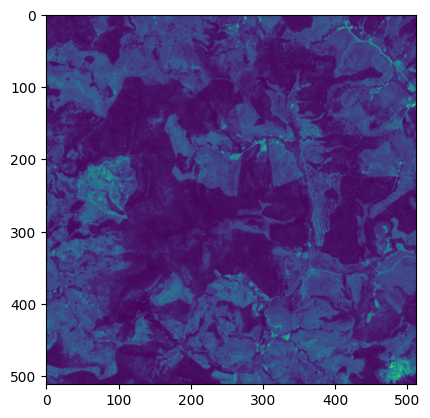

In [ ]:
# Show example train image
plt.imshow((np.array(rxr.open_rasterio(r"{}Test/image/{}".format(base_dir2,test_images_list2[7])))[0,:,:]))

In [ ]:
# Pre-process data, reshaping and transposing
for i in range(len(training_images2)):
  training_images2[i] = training_images2[i].astype('float32')
  training_images2[i] = training_images2[i].T

for i in range(len(training_masks2)):
  training_masks2[i] = training_masks2[i].reshape(1,512,512,1)
  training_masks2[i] = training_masks2[i].T

for i in range(len(validation_images2)):
  validation_images2[i] = validation_images2[i].astype('float32')
  validation_images2[i] = validation_images2[i].T

for i in range(len(validation_masks2)):
  validation_masks2[i] = validation_masks2[i].reshape(1,512,512,1)
  validation_masks2[i] = validation_masks2[i].T

for i in range(len(test_images2)):
  test_images2[i] = test_images2[i].astype('float32')
  test_images2[i] = test_images2[i].T

for i in range(len(test_masks2)):
  test_masks2[i] = test_masks2[i].reshape(1,512,512,1)
  test_masks2[i] = test_masks2[i].T

for i in range(len(training_images2)):
  training_images2[i] = training_images2[i].reshape(-1,512,512,4)

for i in range(len(validation_images2)):
  validation_images2[i] = validation_images2[i].reshape(-1,512,512,4)

for i in range(len(test_images2)):
  test_images2[i] = test_images2[i].reshape(-1,512,512,4)

In [ ]:
# Create TensorFlow datasets for training and validation sets
train_df_4band_amazon = tf.data.Dataset.from_tensor_slices((training_images2[0:250], training_masks2[0:250]))
validation_df_4band_amazon = tf.data.Dataset.from_tensor_slices((validation_images2, validation_masks2))

Model

In [ ]:
import tensorflow as tf

def res_block_initial(x, num_filters, kernel_size, strides, name):
    """Residual Unet block layer for first layer
    In the residual unet the first residual block does not contain an
    initial batch normalization and activation so we create this separate
    block for it.
    Args:
        x: tensor, image or image activation
        num_filters: list, contains the number of filters for each subblock
        kernel_size: int, size of the convolutional kernel
        strides: list, contains the stride for each subblock convolution
        name: name of the layer
    Returns:
        x1: tensor, output from residual connection of x and x1
    """

    if len(num_filters) == 1:
        num_filters = [num_filters[0], num_filters[0]]

    x1 = tf.keras.layers.Conv2D(filters=num_filters[0],
                                kernel_size=kernel_size,
                                strides=strides[0],
                                padding='same',
                                kernel_initializer = 'he_normal',
                                name=name+'_1')(x)
    #x1 = tf.keras.layers.BatchNormalization()(x1)
    x1 = tf.keras.layers.Activation('relu')(x1)
    x1 = tf.keras.layers.Conv2D(filters=num_filters[1],
                                kernel_size=kernel_size,
                                strides=strides[1],
                                padding='same',
                                kernel_initializer = 'he_normal',
                                name=name+'_2')(x1)

    x = tf.keras.layers.Conv2D(filters=num_filters[-1],
                                kernel_size=1,
                                strides=1,
                                padding='same',
                                kernel_initializer = 'he_normal',
                                name=name+'_shortcut')(x)
    #x = tf.keras.layers.BatchNormalization()(x)

    x1 = tf.keras.layers.Add()([x, x1])

    return x1

def res_block(x, num_filters, kernel_size, strides, name):
    """Residual Unet block layer
    Consists of batch norm and relu, folowed by conv, batch norm and relu and
    final convolution. The input is then put through
    Args:
        x: tensor, image or image activation
        num_filters: list, contains the number of filters for each subblock
        kernel_size: int, size of the convolutional kernel
        strides: list, contains the stride for each subblock convolution
        name: name of the layer
    Returns:
        x1: tensor, output from residual connection of x and x1
    """

    if len(num_filters) == 1:
        num_filters = [num_filters[0], num_filters[0]]

    #x1 = tf.keras.layers.BatchNormalization()(x)
    #x1 = tf.keras.layers.Activation('relu')(x1)
    x1 = tf.keras.layers.Activation('relu')(x)
    x1 = tf.keras.layers.Conv2D(filters=num_filters[0],
                                kernel_size=kernel_size,
                                strides=strides[0],
                                padding='same',
                                kernel_initializer = 'he_normal',
                                name=name+'_1')(x1)
    #x1 = tf.keras.layers.BatchNormalization()(x1)
    x1 = tf.keras.layers.Activation('relu')(x1)
    x1 = tf.keras.layers.Conv2D(filters=num_filters[1],
                                kernel_size=kernel_size,
                                strides=strides[1],
                                padding='same',
                                kernel_initializer = 'he_normal',
                                name=name+'_2')(x1)

    x = tf.keras.layers.Conv2D(filters=num_filters[-1],
                                    kernel_size=1,
                                    strides=strides[0],
                                    padding='same',
                                    kernel_initializer = 'he_normal',
                                    name=name+'_shortcut')(x)
    #x = tf.keras.layers.BatchNormalization()(x)

    x1 = tf.keras.layers.Add()([x, x1])

    return x1


def upsample(x, target_size):
    """"Upsampling function, upsamples the feature map
    Deep Residual Unet paper does not describe the upsampling function
    in detail. Original Unet uses a transpose convolution that downsamples
    the number of feature maps. In order to restrict the number of
    parameters here we use a bilinear resampling layer. This results in
    the concatentation layer concatenting feature maps with n and n/2
    features as opposed to n/2  and n/2 in the original unet.
    Args:
        x: tensor, feature map
        target_size: size to resize feature map to
    Returns:
        x_resized: tensor, upsampled feature map
    """

    x_resized = tf.keras.layers.Lambda(lambda x: tf.image.resize(x, target_size))(x)

    return x_resized

def encoder(x, num_filters, kernel_size):
    """Unet encoder
    Args:
        x: tensor, output from previous layer
        num_filters: list, number of filters for each decoder layer
        kernel_size: int, size of the convolutional kernel
    Returns:
        encoder_output: list, output from all encoder layers
    """

    x = res_block_initial(x, [num_filters[0]], kernel_size, strides=[1,1], name='layer1')

    encoder_output = [x]
    for i in range(1, len(num_filters)):
        layer = 'encoder_layer' + str(i)
        x = res_block(x, [num_filters[i]], kernel_size, strides=[2,1], name=layer)
        encoder_output.append(x)

    return encoder_output

def decoder(x, encoder_output, num_filters, kernel_size):
    """Unet decoder
    Args:
        x: tensor, output from previous layer
        encoder_output: list, output from all previous encoder layers
        num_filters: list, number of filters for each decoder layer
        kernel_size: int, size of the convolutional kernel
    Returns:
        x: tensor, output from last layer of decoder
    """

    for i in range(1, len(num_filters) + 1):
        layer = 'decoder_layer' + str(i)
        target_size = encoder_output[-i].shape[1:3]
        x = upsample(x, target_size)
        x = tf.keras.layers.Concatenate(axis=-1)([x, encoder_output[-i]])
        x = res_block(x, [num_filters[-i]], kernel_size, strides=[1,1], name=layer)

    return x


def res_unet(input_size, num_filters, kernel_size, num_channels, num_classes, lr = 0.0001, out_layer = 'sigmoid', lossfunc='binary_crossentropy', num_out=1):
    """Residual Unet
    Function that generates a residual unet
    Args:
        input_size: int, dimension of the input image
        num_layers: int, number of layers in the encoder half, excludes bridge
        num_filters: list, number of filters for each encoder layer
        kernel_size: size of the kernel, applied to all convolutions
        num_channels: int, number of channels for the input image
        num_classes: int, number of output classes for the output
    Returns:
        model: tensorflow keras model for residual unet architecture
    """

    x = tf.keras.Input(shape=[input_size, input_size, num_channels])

    encoder_output = encoder(x, num_filters, kernel_size)

    # bridge layer, number of filters is double that of the last encoder layer
    bridge = res_block(encoder_output[-1], [num_filters[-1]*2], kernel_size,
                        strides=[2,1], name='bridge')

    decoder_output = decoder(bridge, encoder_output, num_filters, kernel_size)

    output = tf.keras.layers.Conv2D(num_classes,
                                    kernel_size,
                                    strides=1,
                                    padding='same',
                                    kernel_initializer = 'he_normal',
                                    name='output')(decoder_output)

    output = Activation(out_layer)(output)

    model = tf.keras.Model(x, output)
    model.compile(optimizer = adam_v2.Adam(learning_rate = lr), loss = lossfunc, metrics=['accuracy', 'mse'])

    return model

In [ ]:

res_unet(512, [64, 128, 256, 512], 3, 3, 1).summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 512, 512, 3  0           []                               
                                )]                                                                
                                                                                                  
 layer1_1 (Conv2D)              (None, 512, 512, 64  1792        ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 activation (Activation)        (None, 512, 512, 64  0           ['layer1_1[0][0]']               
                                )                                                             

Train on 4-band Atlantic data

In [ ]:
R_4band = res_unet(512, [64, 128, 256, 512], 3, 4, 1)
import time
start_time = time.time()

save_model_resunet_4band = ModelCheckpoint('resunet-4d.hdf5', monitor='val_accuracy',verbose=1, save_best_only=True, save_weights_only=True)
R_4band.fit(train_df_4band_amazon, validation_data = validation_df_4band_amazon, epochs = 10, callbacks=[save_model_resunet_4band])

end_time = time.time()

total_time = end_time - start_time
print("Total training time (sec):", total_time)

Epoch 1/10
250/250 [==============================] - ETA: 0s - loss: 2.3252 - accuracy: 0.8449 - mse: 0.1247
Epoch 1: val_accuracy improved from -inf to 0.84554, saving model to resunet-4d.hdf5
250/250 [==============================] - 755s 3s/step - loss: 2.3252 - accuracy: 0.8449 - mse: 0.1247 - val_loss: 0.6348 - val_accuracy: 0.8455 - val_mse: 0.1291
Epoch 2/10
250/250 [==============================] - ETA: 0s - loss: 0.2067 - accuracy: 0.9162 - mse: 0.0614
Epoch 2: val_accuracy improved from 0.84554 to 0.86050, saving model to resunet-4d.hdf5
250/250 [==============================] - 808s 3s/step - loss: 0.2067 - accuracy: 0.9162 - mse: 0.0614 - val_loss: 0.5967 - val_accuracy: 0.8605 - val_mse: 0.1177
Epoch 3/10
250/250 [==============================] - ETA: 0s - loss: 0.1691 - accuracy: 0.9308 - mse: 0.0505
Epoch 3: val_accuracy improved from 0.86050 to 0.87082, saving model to resunet-4d.hdf5
250/250 [==============================] - 729s 3s/step - loss: 0.1691 - accuracy

In [ ]:
# Save model history
np.save('resunet-4d-history.npy', R_4band.history.history)

Import Models and Compute Metrics

In [ ]:
# Load ResUNet models and history stats
# Import models
#resunet_3d = res_unet(512, [64, 128, 256, 512], 3, 3, 1)
resunet_4d_amazon = res_unet(512, [64, 128, 256, 512], 3, 4, 1)
#resunet_4d_atlantic = res_unet(512, [64, 128, 256, 512], 3, 4, 1)
#resunet_3d.load_weights('resunet-3d.hdf5')
resunet_4d_amazon.load_weights('resunet-4d.hdf5')
#resunet_4d_atlantic.load_weights('resunet-4d-atlantic.hdf5')

#resunet_3d_history = np.load('resunet-3d-history.npy', allow_pickle='TRUE').item()
resunet_4d_amazon_history = np.load('resunet-4d-history.npy', allow_pickle='TRUE').item()
#resunet_4d_atlantic_history = np.load('resunet-4d-atlantic-history.npy', allow_pickle='TRUE').item()

In [ ]:
# Metrics of each model on respective datasets

# Score
#resunet_3d_score = (score_eval(resunet_3d, validation_images, validation_masks))
resunet_4d_amazon_score = (score_eval2(resunet_4d_amazon, validation_images2, validation_masks2))
#resunet_4d_atlantic_score = (score_eval2(resunet_4d_atlantic, validation_images3, validation_masks3))

# Precision and recall
#resunet_3d_precision = (precision_eval(resunet_3d, validation_images, validation_masks))
resunet_4d_amazon_precision = (precision_eval(resunet_4d_amazon, validation_images2, validation_masks2))
#resunet_4d_atlantic_precision = (precision_eval(resunet_4d_atlantic, validation_images3, validation_masks3))

#resunet_3d_recall = (recall_eval(resunet_3d, validation_images, validation_masks))
resunet_4d_amazon_recall = (recall_eval(resunet_4d_amazon, validation_images2, validation_masks2))
#resunet_4d_atlantic_recall = (recall_eval(resunet_4d_atlantic, validation_images3, validation_masks3))

# F1-score
#resunet_3d_f1_score = (f1_score_eval_basic(resunet_3d_precision, resnet_3d_recall))
resunet_4d_amazon_f1_score = (f1_score_eval_basic(resunet_4d_amazon_precision, resunet_4d_amazon_recall))
#resunet_4d_atlantic_f1_score = (f1_score_eval_basic(resunet_4d_atlantic_precision, resnet_4d_atlantic_recall))

1/1 [==============================] - 1s 515ms/step


In [ ]:
# Print score eval results for each model
print('ResU-Net accuracy: ', np.mean(resunet_4d_amazon_score), np.std(resunet_4d_amazon_score))

# Print precision eval results for each model
print('ResU-Net precision: ', np.mean(resunet_4d_amazon_precision), np.std(resunet_4d_amazon_precision))

# Print recall eval results for each model
print('ResU-Net recall: ', np.mean(resunet_4d_amazon_recall), np.std(resunet_4d_amazon_recall))


# Print f1-score eval results for each model
print('ResU-Net F1-score: ', np.mean(resunet_4d_amazon_f1_score))

ResU-Net accuracy:  0.8824303817749023 0.11137501564891988
ResU-Net precision:  0.9264807920515288 0.043763730407164574
ResU-Net recall:  0.8824303817749023 0.11137501564891988
ResU-Net F1-score:  0.9039192314874722


In [ ]:

# Print metrics
print('Accuracy | Precision | Recall | F1-score')

print('ResUNet 4-dim Amazon (mean): ', np.mean(resunet_4d_amazon_score), np.mean(resunet_4d_amazon_precision), np.mean(resunet_4d_amazon_recall), resunet_4d_amazon_f1_score)
print('ResUNet 4-dim Amazon (std): ', np.std(resunet_4d_amazon_score), np.std(resunet_4d_amazon_precision), np.std(resunet_4d_amazon_recall), resunet_4d_amazon_f1_score)


Accuracy | Precision | Recall | F1-score
ResUNet 4-dim Amazon (mean):  0.8824303817749023 0.9264807920515288 0.8824303817749023 0.9039192314874722
ResUNet 4-dim Amazon (std):  0.11137501564891988 0.043763730407164574 0.11137501564891988 0.9039192314874722


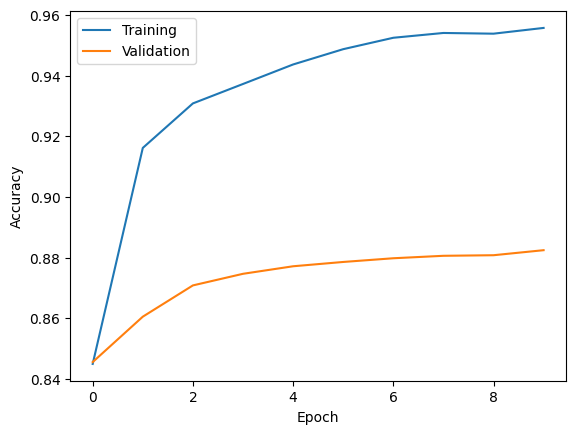

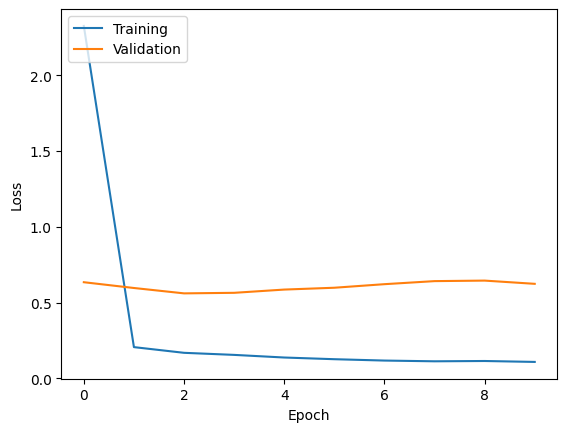

In [ ]:
# Plot accuracy and loss for U-Net

## Accuracy
plt.plot(resunet_4d_amazon_history['accuracy'])
plt.plot(resunet_4d_amazon_history['val_accuracy'])
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Training', 'Validation'], loc='upper left')
plt.show()

## Loss
plt.plot(resunet_4d_amazon_history['loss'])
plt.plot(resunet_4d_amazon_history['val_loss'])
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Training', 'Validation'], loc='upper left')

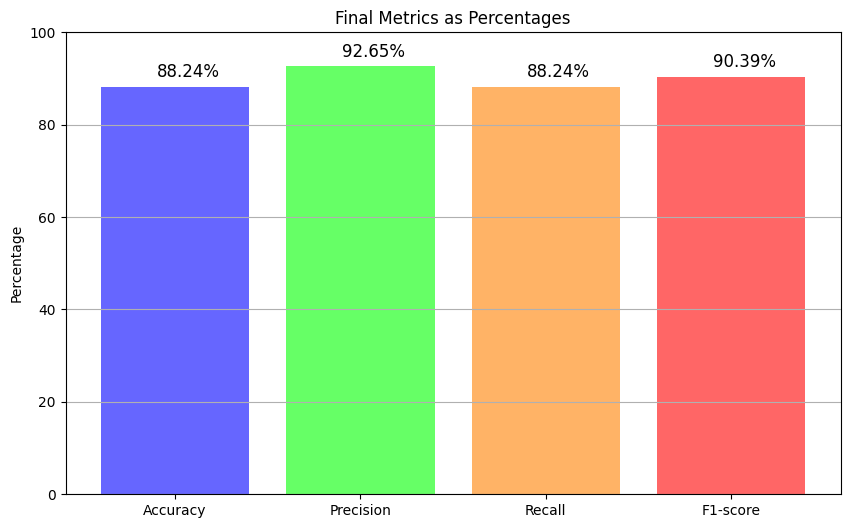

In [ ]:
# Assuming you have calculated these metrics for your model
#epochs = 10
accuracy = np.mean(resunet_4d_amazon_score)*100
precision = np.mean(resunet_4d_amazon_precision)*100
recall = np.mean(resunet_4d_amazon_recall)*100
f1_score = resunet_4d_amazon_f1_score*100
# List of metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']

# Corresponding values for each metric
values = [accuracy, precision, recall, f1_score]

plt.figure(figsize=(10, 6))

# Define lighter shades of colors
light_blue = (0.4, 0.4, 1.0)  # Light blue
light_green = (0.4, 1.0, 0.4)  # Light green
light_orange = (1.0, 0.7, 0.4)  # Light orange
light_red = (1.0, 0.4, 0.4)  # Light red

# Create bar plot with light colors
bars = plt.bar(metrics, values, color=[light_blue, light_green, light_orange, light_red])

plt.title('Final Metrics as Percentages')
plt.ylabel('Percentage')
plt.ylim(0, 100)  # Set the y-axis range to 0-100%
plt.grid(axis='y')

for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2 - 0.1, value + 2, f'{value:.2f}%', fontsize=12, color='black')

plt.show()

In [ ]:
# Assuming you have already imported necessary libraries and defined your ResUNet model (R_4band)

predictions = []

# Iterate over each preprocessed test image
for i in range(len(test_images2)):
    # Make prediction using the model
    prediction = resunet_4d_amazon.predict(test_images2[i])

    # Append the prediction to the list of predictions
    predictions.append(prediction)

# Now, 'predictions' will contain the predictions for each test image

1/1 [==============================] - 1s 514ms/step


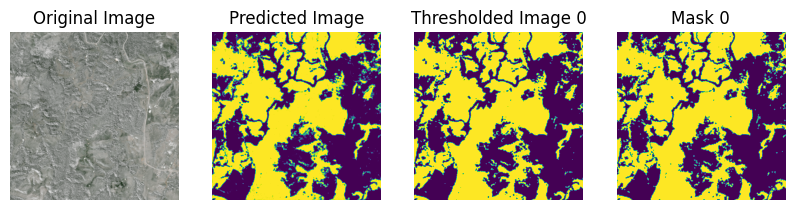

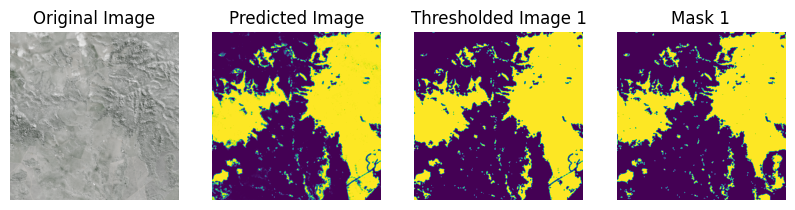

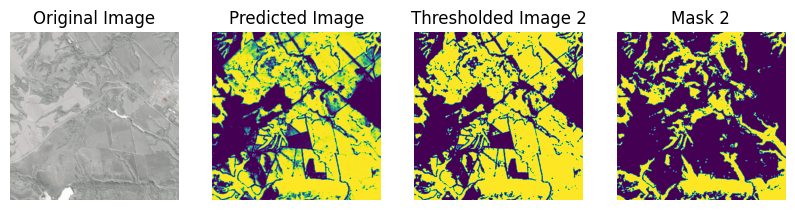

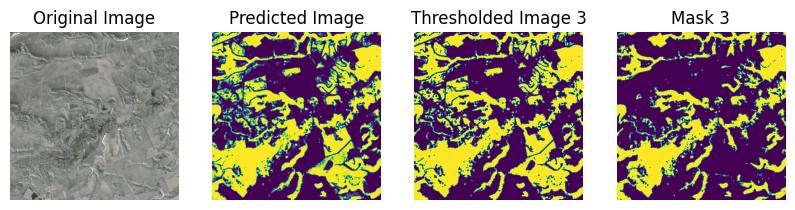

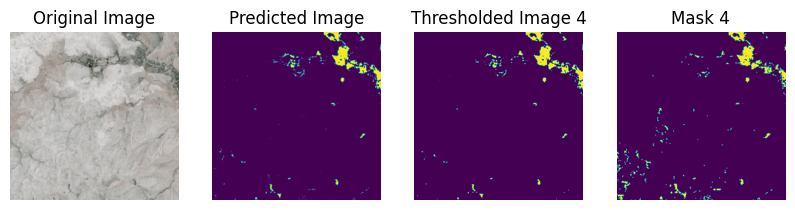

...

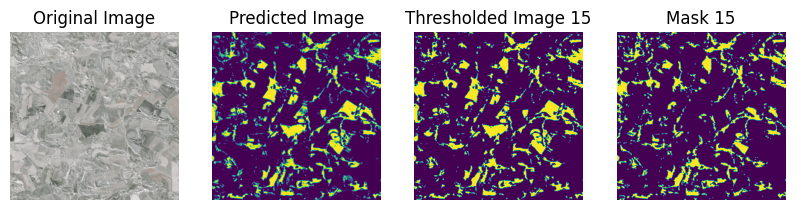

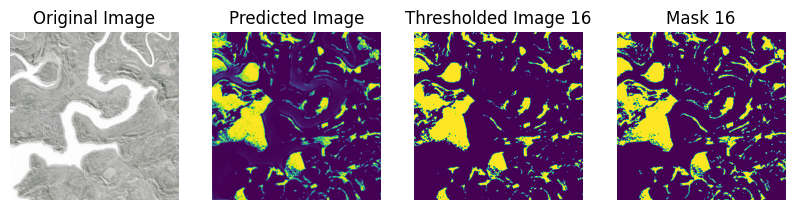

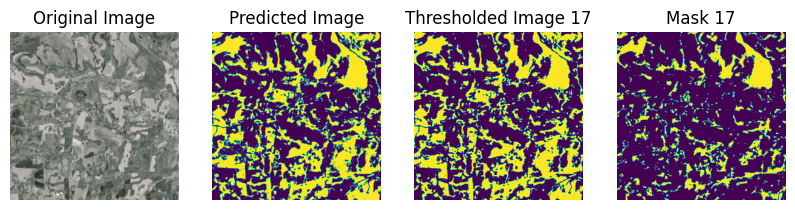

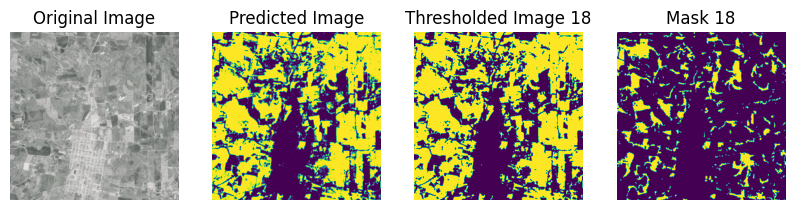

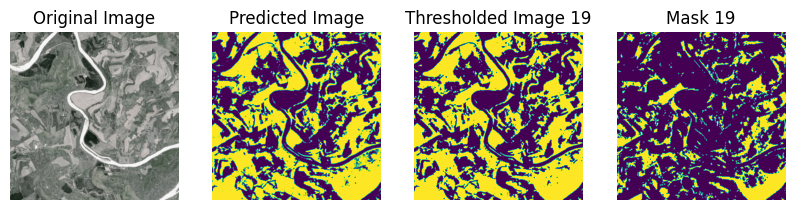

In [ ]:
import cv2
import numpy as np

# Threshold value
threshold = 0.5  # Assuming predictions are probabilities

# Assuming 'predictions' contains the predictions for each test image
# and 'test_images' contains the preprocessed test images
for i in range(len(predictions)):
    # Extract the predicted image array
    predicted_image_array = predictions[i][0]

    # Apply binary thresholding
    binary_predicted_image_array = np.where(predicted_image_array > threshold, 1, 0)

    # Rotate by 90 degrees clockwise and flip up-down
    rotated_flipped_image = np.flipud(np.rot90(binary_predicted_image_array, k=1))

    plt.figure(figsize=(10, 5))

    # Original Image
    plt.subplot(1, 4, 1)
    plt.title('Original Image')
    plt.imshow(np.flipud(np.rot90(test_images2[i][0], k=1)))  # Rotate and flip the original image
    plt.axis('off')

    # Predicted Image
    plt.subplot(1, 4, 2)
    plt.title('Predicted Image')
    plt.imshow(np.flipud(np.rot90(predictions[i][0], k=1)))  # Rotate and flip the predicted image
    plt.axis('off')

    # Plot the binary predicted image
    plt.subplot(1, 4, 3)
    plt.imshow(rotated_flipped_image.squeeze())
    plt.title(f'Thresholded Image {i}')
    plt.axis('off')

    # Plot the masked image
    plt.subplot(1, 4, 4)
    plt.title(f'Mask {i}')
    plt.imshow(np.flipud(np.rot90(test_masks2[i][0], k=1)))  # Rotate and flip the mask image
    plt.axis('off')

    plt.show()


Save

In [ ]:
mask=test_masks2[1]
main_image=test_images2[1]
pred = resunet_4d_amazon.predict(test_images2[1])

1/1 [==============================] - 1s 518ms/step


Extra


In [ ]:
import cv2

In [ ]:
prediction=pred

# Assuming 'mask' is your image with shape (1, 512, 512, 1)
prediction = np.squeeze(prediction, axis=0)  # Remove the batch dimension
# Squeeze out the channel dimension if it's a grayscale image
if prediction.shape[-1] == 1:
    prediction = np.squeeze(prediction, axis=-1)

# Assuming 'prediction' is now your final predicted image
# Rescale the image back to the original range if needed
prediction_rescaled = prediction * 255.0

# Convert the image to uint8 format
prediction_rescaled = prediction_rescaled.astype('uint8')

# If the image has only one channel, duplicate it to create a 3-channel image
if len(prediction_rescaled.shape) == 2:
    prediction_rescaled = cv2.cvtColor(prediction_rescaled, cv2.COLOR_GRAY2RGB)

# Save the image as TIFF
cv2.imwrite('predicted_image_1.tiff', prediction_rescaled)


True

In [ ]:


# Assuming 'mask' is your image with shape (1, 512, 512, 1)
mask = np.squeeze(mask, axis=0)  # Remove the batch dimension

# Squeeze out the channel dimension if it's a grayscale image
if mask.shape[-1] == 1:
    mask = np.squeeze(mask, axis=-1)

# Assuming 'mask' is now your final image
# Rescale the image back to the original range if needed
# Here's just an example, you might need to adapt it to your specific case
mask_rescaled = mask * 255.0

# Convert the image to uint8 format
mask_rescaled = mask_rescaled.astype('uint8')

# Save the image as TIFF
cv2.imwrite('mask_image_1.tiff', mask_rescaled)


True

In [ ]:
# Assuming you have already imported necessary libraries and defined your ResUNet model (R_4band)

predictions = []

# Iterate over each preprocessed test image
for i in range(len(test_images2)):
    # Make prediction using the model
    prediction = resunet_4d_amazon.predict(test_images2[i])

    # Append the prediction to the list of predictions
    predictions.append(prediction)

# Now, 'predictions' will contain the predictions for each test image

1/1 [==============================] - 1s 512ms/step


In [ ]:
original=main_image

# Assuming 'original' is your image with shape (1, 512, 512, 1)
original = np.squeeze(original, axis=0)  # Remove the batch dimension

# Squeeze out the channel dimension if it's a grayscale image
if original.shape[-1] == 1:
    original = np.squeeze(original, axis=-1)

# Assuming 'original' is now your final image
# Rescale the image back to the original range if needed
# Here's just an example, you might need to adapt it to your specific case
original_rescaled = original * 255.0

# Convert the image to uint8 format
original_rescaled = original_rescaled.astype('uint8')

# Save the image as TIFF
cv2.imwrite('original_image_1.tiff', original_rescaled)

True

1/1 [==============================] - 1s 858ms/step


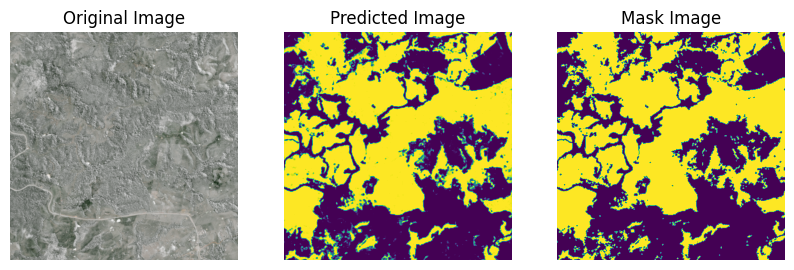

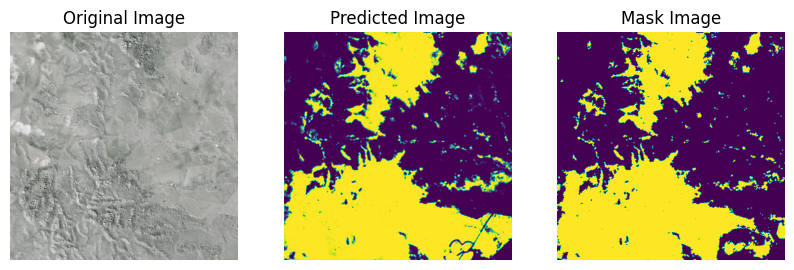

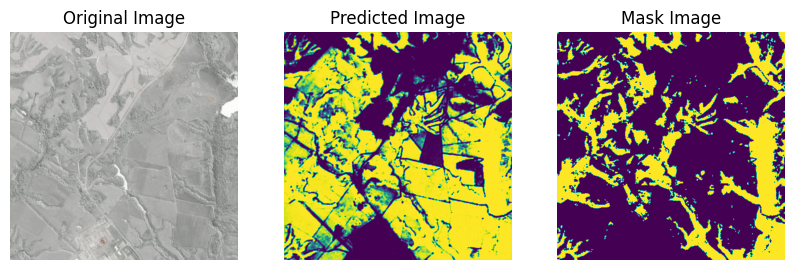

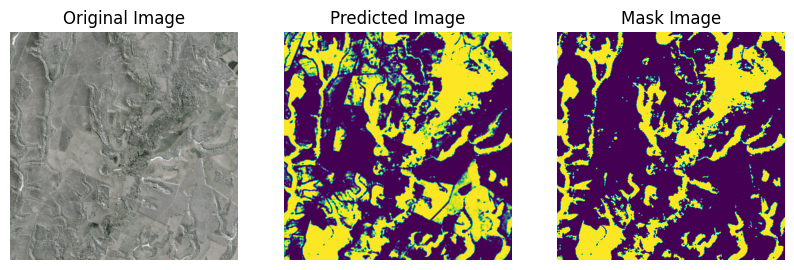

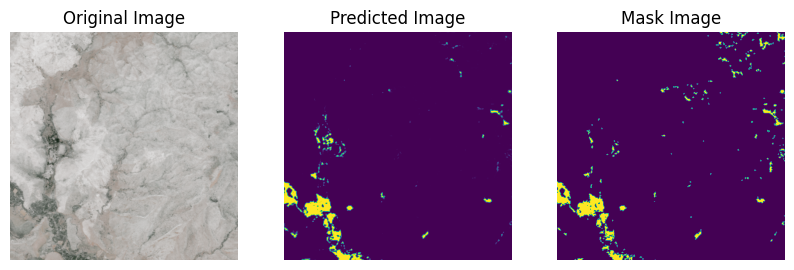

...

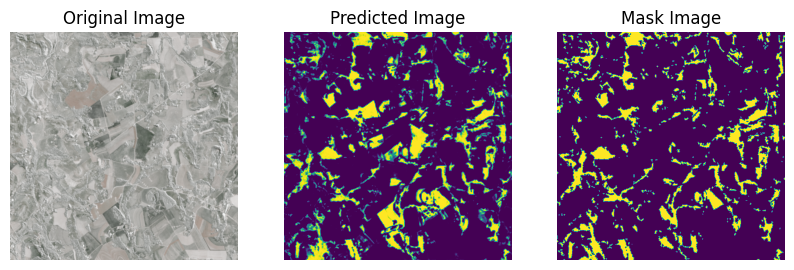

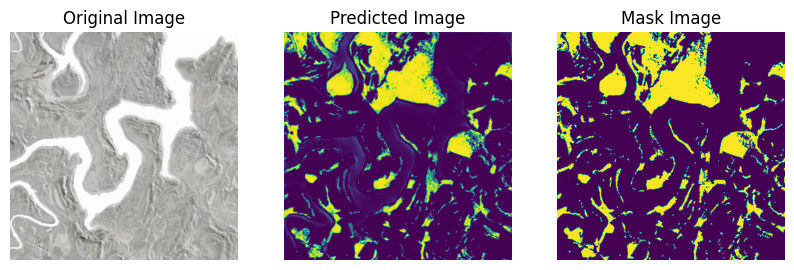

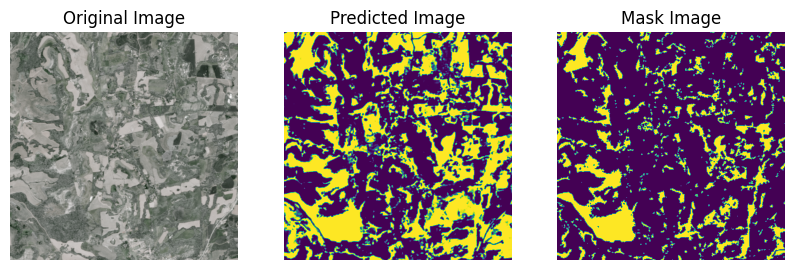

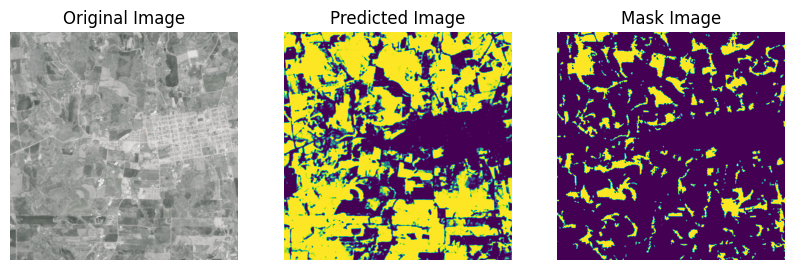

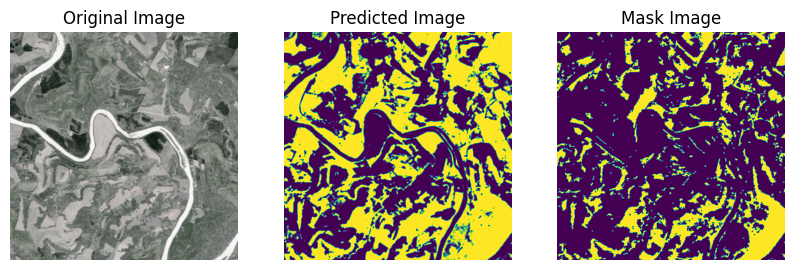

In [ ]:
import matplotlib.pyplot as plt

# Assuming 'predictions' contains the predictions for each test image
# and 'test_images' contains the preprocessed test images
output_folder = 'E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold/'

# Plot the original and predicted images
for i in range(len(test_images2)):
    plt.figure(figsize=(10, 5))

    # Original Image
    plt.subplot(1, 3, 1)
    plt.title('Original Image')
    plt.imshow(test_images2[i][0])  # Assuming your test_images are of shape (1, 512, 512, 3)
    plt.axis('off')

    # Predicted Image
    plt.subplot(1, 3, 2)
    plt.title('Predicted Image')
    plt.imshow(predictions[i][0])  # Assuming your predictions are of shape (1, 512, 512, num_classes)
    plt.axis('off')


    # Predicted Image
    plt.subplot(1, 3, 3)
    plt.title('Mask Image')
    plt.imshow(test_masks2[i][0])  # Assuming your predictions are of shape (1, 512, 512, num_classes)
    plt.axis('off')

    plt.show()


Saving to a folder

In [ ]:
import os
import numpy as np
import tifffile

# Assuming 'predictions' is a list of prediction arrays
for i, prediction in enumerate(predictions):
    # Create a filename for the TIFF file
    filename = os.path.join('E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold', f'prediction_{i}.tiff')

    # Convert prediction array to uint8 (adjust as needed)
    prediction_uint8 = (prediction * 255).astype(np.uint8)

    # Save the prediction as a TIFF file
    tifffile.imwrite(filename, prediction_uint8)

    print(f"Saved prediction {i} to {filename}")

Saved prediction 0 to E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold\prediction_0.tiff
Saved prediction 1 to E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold\prediction_1.tiff
Saved prediction 2 to E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold\prediction_2.tiff
Saved prediction 3 to E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold\prediction_3.tiff
Saved prediction 4 to E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold\prediction_4.tiff
Saved prediction 5 to E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold\prediction_5.tiff
Saved prediction 6 to E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold\prediction_6.tiff
Saved prediction 7 to E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold\prediction_7.tiff
Saved prediction 8 to E:/Atlantic_Codes/Atlantic_ResUNet_4band/predictions_4d_no_threshold\prediction_8.tiff
Saved prediction 9 

In [ ]:
save_dir = "E:/Atlantic_Codes/Atlantic_ResUNet_4band/predicted_with_threshold/"

In [ ]:
import os
import numpy as np
from PIL import Image


# Create the directory if it doesn't exist
os.makedirs(save_dir, exist_ok=True)

# Threshold value
threshold = 127
# Assuming 'predictions' contains the predictions for each test image
# and 'test_images' contains the preprocessed test images

for i in range(len(predictions)):
    # Extract the predicted image array and scale it to the range [0, 255]
    predicted_image_array = (predictions[i][0] * 255).astype(np.uint8)

    # Apply binary thresholding
    binary_predicted_image_array = np.where(predicted_image_array > threshold, 255, 0).astype(np.uint8)

    # Convert the binary image array to a PIL image
    predicted_image = Image.fromarray(binary_predicted_image_array.squeeze(), mode='L')

    # Save the predicted image in the specified directory
    predicted_image.save(os.path.join(save_dir, f'predicted_image_{i}.png'))

# The predicted images will be saved in the directory specified by 'save_dir'

In [ ]:
save_dir = "E:/Atlantic_Codes/Atlantic_ResUNet_4band/original_images/"

In [ ]:
import os
import numpy as np
from tifffile import imsave

# Create the directory if it doesn't exist
os.makedirs(save_dir, exist_ok=True)

# Save each band of the original images as TIFF files
for i, image_array in enumerate(test_images2):
    # Assuming the image_array has shape (1, height, width, 4) with RGBA channels
    for band_idx, band_name in enumerate(['red', 'green', 'blue', 'nir']):
        # Extract the band
        band = image_array[..., band_idx]

        # Save the band as a TIFF file in the specified directory
        save_path = os.path.join(save_dir, f'original_image_{i}_{band_name}.tiff')
        imsave(save_path, band.squeeze())

# The bands of the original images will be saved as TIFF files in the directory specified by 'save_dir'


C:\Users\T20101537\AppData\Local\Temp\ipykernel_25348\2288856502.py:17: DeprecationWarning: <tifffile.imsave> is deprecated. Use tifffile.imwrite
  imsave(save_path, band.squeeze())


Error opening S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_20200111T164651_01_06.tif: cannot identify image file 'E:/Thesis/Unet/AMAZON/Test/image/S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_20200111T164651_01_06.tif'
Error opening S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_20200111T164651_04_19.tif: cannot identify image file 'E:/Thesis/Unet/AMAZON/Test/image/S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_20200111T164651_04_19.tif'
Error opening S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_20200111T164651_08_03.tif: cannot identify image file 'E:/Thesis/Unet/AMAZON/Test/image/S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_20200111T164651_08_03.tif'
Error opening S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_20200111T164651_19_09.tif: cannot identify image file 'E:/Thesis/Unet/AMAZON/Test/image/S2A_MSIL2A_20200111T142701_N0213_R053_T20NQG_20200111T164651_19_09.tif'
Error opening S2A_MSIL2A_20200217T141651_N0209_R010_T20LQN_20200217T160045_01_20.tif: cannot identify image file 'E:/Thesis/